# Wine Quality Prediction and Feature Importance Analysis Using Random Forest
**MACHINE LEARNING (25CS2107E)** — *Y25 2026-2027 Trimester - 4*  
**Sec No:** 5 | **Team No:** 64  
**Team Members:** Sura.Rahul Reddy (2520030305), Yashwanth (2520030506)

---

### 1. Abstract
The determination of the quality of wine has been a challenging issue as it is performed through expert sensory panels, which are subjective and hard to automate. The proposed work attempts to determine wine quality through a supervised machine learning approach by applying a Random Forest algorithm and determining the importance of physicochemical factors (alcohol, volatile acidity, citric acid, sulphates, pH) for predicting the wine quality from the UCI Wine Quality dataset.

Apart from the predictive performance of the model, the importance of each factor will be analyzed based on the Gini importance measure, and the results will be validated against scientific knowledge about wine production. The performance of the classification model will be measured based on accuracy, precision, recall, F1-score, and a confusion matrix using k-fold cross-validation.

Thus, by combining the predictive performance of the model with its explainability and feature level importance measures, the research illustrates how ensemble learning approaches could become more than just black box models in the context of practical tasks.

---

**Goal:** predict whether a wine is *good* or *poor* from its physicochemical properties, and find out **which properties matter most** for quality.

**Dataset:** UCI Wine Quality (Vinho Verde) — 1,599 red + 4,898 white wines, 11 lab measurements each, plus a sensory quality score (0–10) given by expert tasters.

**Pipeline**
1. Load & combine red and white data
2. Exploratory data analysis (EDA)
3. Cleaning (remove duplicates)
4. Feature / target preparation and stratified train–test split
5. Baseline Random Forest → cross-validation → comparison with simpler models
6. Hyperparameter tuning
7. Final evaluation, **feature importance** (Gini + permutation)
8. Regression view, saving the trained model, predicting a new wine


## Step 1 — Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Step 2 — Load the Data
Works in **Google Colab** (upload `wine+quality.zip` when prompted) or **locally** (put `winequality-red.csv` and `winequality-white.csv` in a `wine_data/` folder, or put the zip next to the notebook).

In [2]:
import os, zipfile

if not (os.path.exists("wine_data/winequality-red.csv") and os.path.exists("wine_data/winequality-white.csv")):
    zips = [f for f in os.listdir(".") if f.endswith(".zip") and "wine" in f.lower()]
    if not zips:
        try:                                        # Google Colab upload
            from google.colab import files
            zips = list(files.upload().keys())
        except ImportError:
            raise FileNotFoundError("Place wine+quality.zip or the two CSVs in ./wine_data/")
    with zipfile.ZipFile(zips[0]) as z:
        z.extractall("wine_data")

print(os.listdir("wine_data"))

red   = pd.read_csv("wine_data/winequality-red.csv",   sep=";")
white = pd.read_csv("wine_data/winequality-white.csv", sep=";")
red["wine_type"], white["wine_type"] = "Red", "White"

df = pd.concat([red, white], ignore_index=True)
df.head()

['winequality-white.csv', 'winequality-red.csv']


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,Red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,Red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,Red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,Red


## Step 3 — Dataset Overview

In [3]:
print("Rows:", df.shape[0]); print("Columns:", df.shape[1])
print(df.columns.tolist())
df.info()

Rows: 6497
Columns: 13
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'wine_type']
<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality          

In [4]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


In [5]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nQuality distribution:\n", df["quality"].value_counts().sort_index())
print("\nWine type distribution:\n", df["wine_type"].value_counts())

Missing values: 0
Duplicate rows: 1177

Quality distribution:
 quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Wine type distribution:
 wine_type
White    4898
Red      1599
Name: count, dtype: int64


## Step 4 — Exploratory Data Analysis

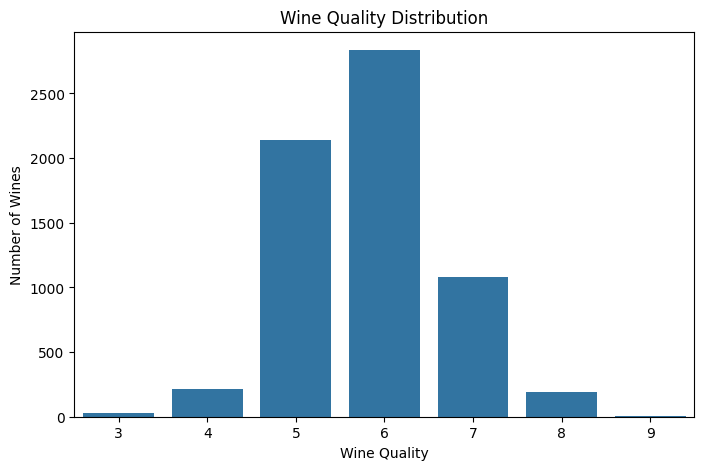

In [6]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="quality")

plt.title("Wine Quality Distribution")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")

plt.show()

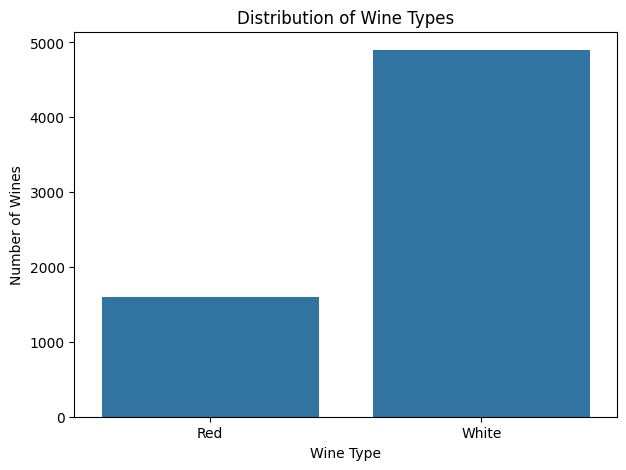

In [7]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x="wine_type")

plt.title("Distribution of Wine Types")
plt.xlabel("Wine Type")
plt.ylabel("Number of Wines")

plt.show()

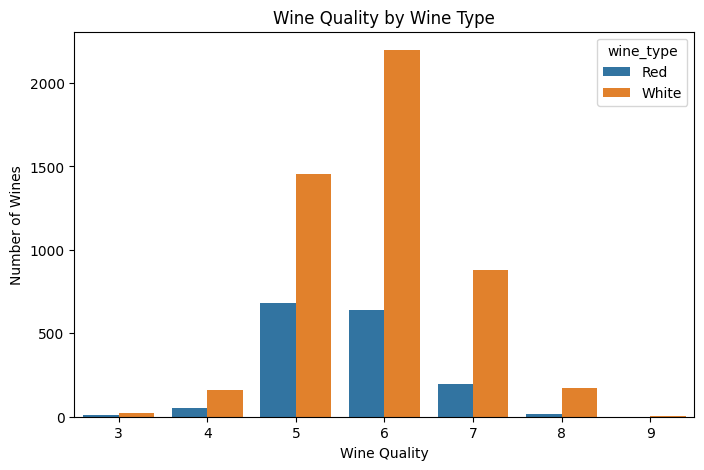

In [8]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="quality",
    hue="wine_type"
)

plt.title("Wine Quality by Wine Type")
plt.xlabel("Wine Quality")
plt.ylabel("Number of Wines")

plt.show()

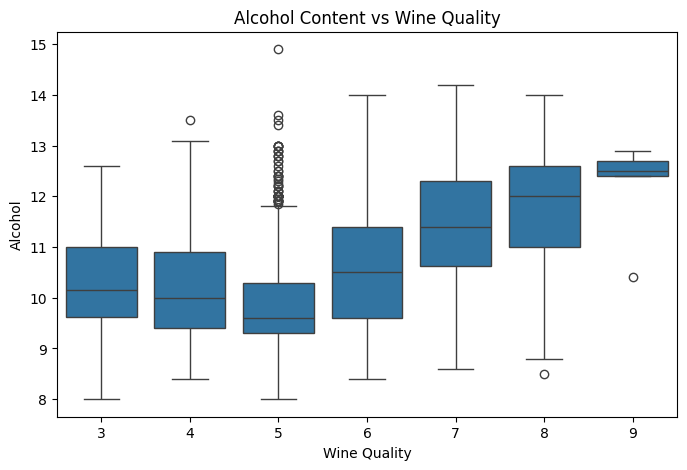

In [9]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="quality",
    y="alcohol"
)

plt.title("Alcohol Content vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Alcohol")

plt.show()

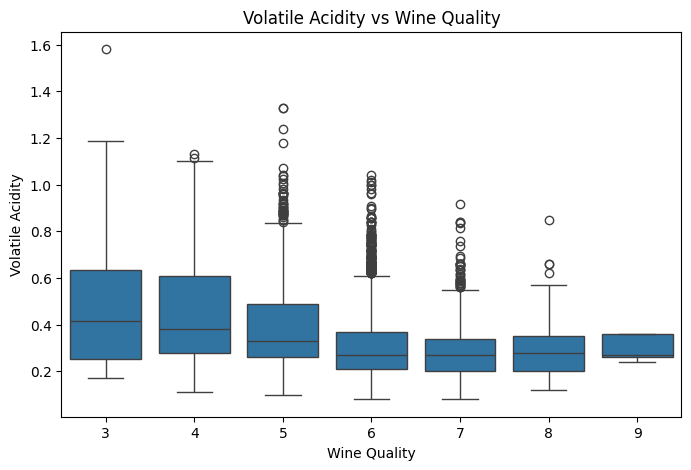

In [10]:
plt.figure(figsize=(8,5))

sns.boxplot(
    data=df,
    x="quality",
    y="volatile acidity"
)

plt.title("Volatile Acidity vs Wine Quality")
plt.xlabel("Wine Quality")
plt.ylabel("Volatile Acidity")

plt.show()

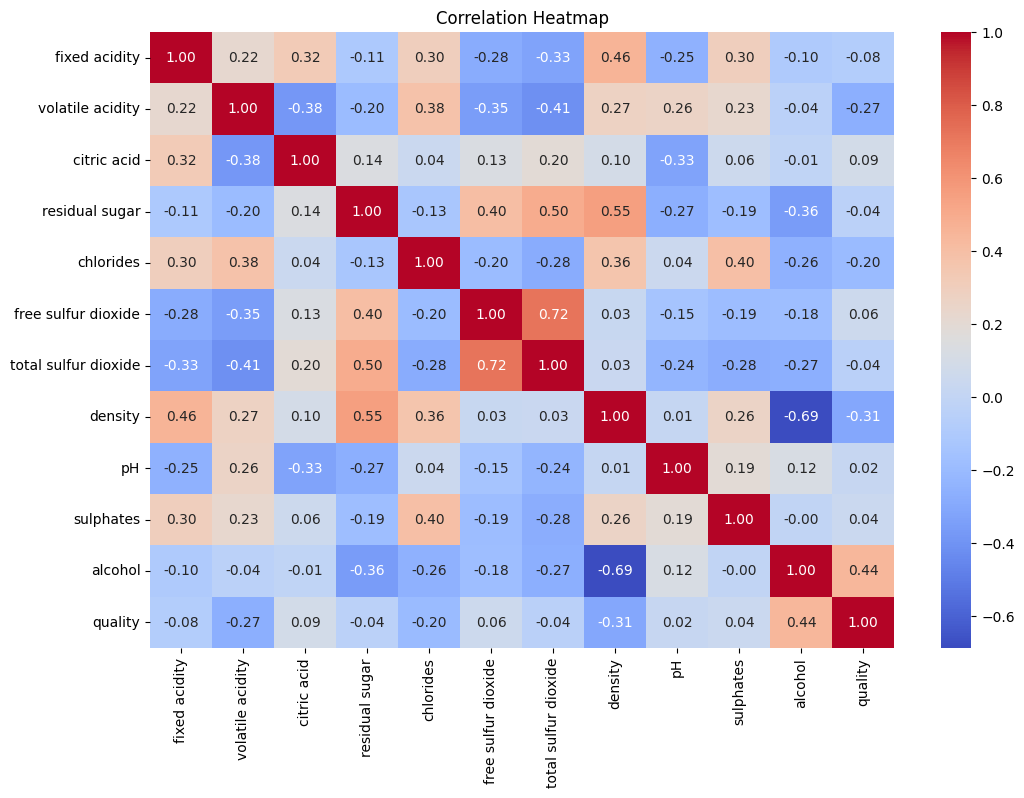

In [11]:
plt.figure(figsize=(12,8))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [12]:
quality_correlation = (
    df.select_dtypes(include=np.number)
      .corr()["quality"]
      .sort_values(ascending=False)
)

print(quality_correlation)

quality                 1.000000
alcohol                 0.444319
citric acid             0.085532
free sulfur dioxide     0.055463
sulphates               0.038485
pH                      0.019506
residual sugar         -0.036980
total sulfur dioxide   -0.041385
fixed acidity          -0.076743
chlorides              -0.200666
volatile acidity       -0.265699
density                -0.305858
Name: quality, dtype: float64


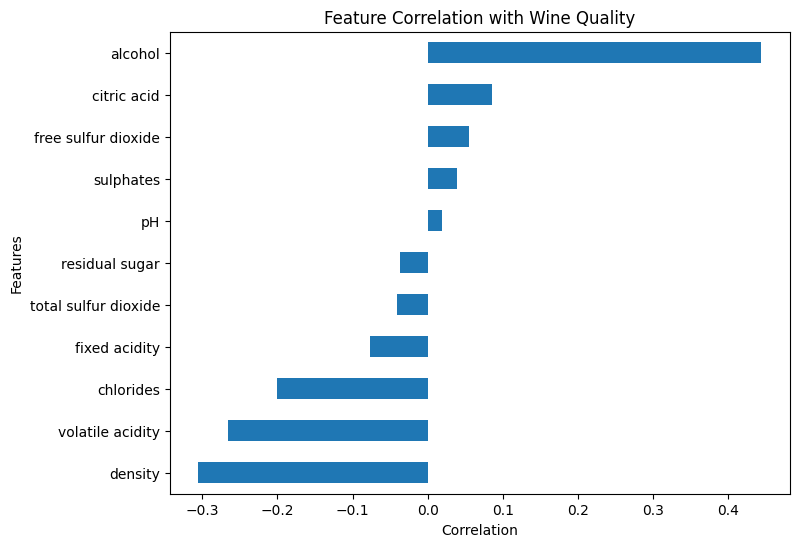

In [13]:
plt.figure(figsize=(8,6))

quality_correlation.drop("quality").sort_values().plot(
    kind="barh"
)

plt.title("Feature Correlation with Wine Quality")
plt.xlabel("Correlation")
plt.ylabel("Features")

plt.show()

**EDA takeaways:** quality is concentrated at 5–7 (imbalanced at the extremes); **alcohol** has the strongest positive correlation with quality and **volatile acidity** / **density** are negatively related; white wines outnumber red about 3 : 1; 1,177 rows are exact duplicates and are removed next.

## Step 5 — Data Cleaning (remove duplicates)

In [14]:
print("Missing values per column:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

df_clean = df.dropna()

print("\nDuplicate rows before removal:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print("Duplicate rows after removal:", df_clean.duplicated().sum())
print("Missing values after cleaning:", df_clean.isnull().sum().sum())
print("Shape before:", df.shape)
print("Shape after: ", df_clean.shape)

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64
Total missing values: 0

Duplicate rows before removal: 1177
Duplicate rows after removal: 0
Missing values after cleaning: 0
Shape before: (6497, 13)
Shape after:  (5320, 13)


## Step 6 — Prepare Features & Target
- `wine_type` is encoded as `is_white` (Red = 0, White = 1)
- **Classification target:** `good_quality` = 1 if quality ≥ `GOOD_THRESHOLD`, else 0 (6 gives balanced classes; use 7 for "premium" wines only)
- **Regression target:** the raw `quality` score

In [15]:
import warnings; warnings.filterwarnings("ignore")
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, roc_curve, roc_auc_score, mean_squared_error, mean_absolute_error, r2_score)
from sklearn.inspection import permutation_importance

SEED = 42
GOOD_THRESHOLD = 6          # change to 7 for "premium" vs rest

data = df_clean.copy()
data["is_white"] = (data["wine_type"] == "White").astype(int)
data["good_quality"] = (data["quality"] >= GOOD_THRESHOLD).astype(int)

FEATURES = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
            'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'is_white']

X = data[FEATURES]
y = data["good_quality"]

print("Features:", X.shape, " Target:", y.shape)
print("\nClass balance (%):")
print((y.value_counts(normalize=True).sort_index() * 100).round(2).rename({0: "Poor", 1: "Good"}))

Features: (5320, 12)  Target: (5320,)

Class balance (%):
good_quality
Poor    37.37
Good    62.63
Name: proportion, dtype: float64


## Step 7 — Train / Test Split (80 / 20, stratified)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Training set:", X_train.shape)
print("Testing set: ", X_test.shape)

Training set: (4256, 12)
Testing set:  (1064, 12)


## Step 8 — Baseline Random Forest

In [17]:
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_test)
print("Baseline Random Forest")
print("Train accuracy:", round(rf.score(X_train, y_train), 4))
print("Test accuracy: ", round(accuracy_score(y_test, y_pred), 4))
print("\n", classification_report(y_test, y_pred, target_names=["Poor", "Good"], digits=3))

Baseline Random Forest
Train accuracy: 1.0
Test accuracy:  0.7716

               precision    recall  f1-score   support

        Poor      0.717     0.643     0.678       398
        Good      0.799     0.848     0.823       666

    accuracy                          0.772      1064
   macro avg      0.758     0.746     0.751      1064
weighted avg      0.768     0.772     0.769      1064



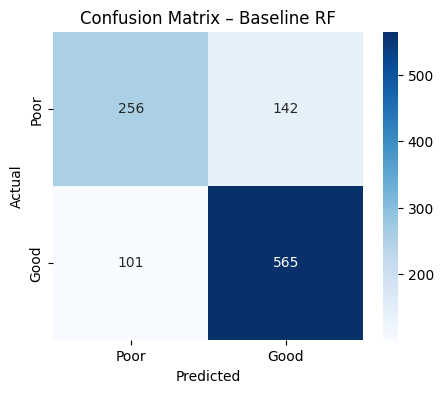

In [18]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Poor", "Good"], yticklabels=["Poor", "Good"])
plt.title("Confusion Matrix – Baseline RF")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.show()

The baseline forest scores 100 % on training data but ~77 % on test data — a sign of overfitting that tuning and cross-validation help us judge.

## Step 9 — Cross-Validation (5-fold, to check the score is stable)

In [19]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(rf, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
cv_f1 = cross_val_score(rf, X_train, y_train, cv=cv, scoring="f1", n_jobs=-1)
print("CV accuracy per fold:", cv_acc.round(4))
print(f"Mean CV accuracy: {cv_acc.mean():.4f} (+/- {cv_acc.std():.4f})")
print(f"Mean CV F1:       {cv_f1.mean():.4f} (+/- {cv_f1.std():.4f})")

CV accuracy per fold: [0.784  0.7897 0.7685 0.765  0.7532]
Mean CV accuracy: 0.7721 (+/- 0.0132)
Mean CV F1:       0.8223 (+/- 0.0115)


## Step 10 — Compare with Simpler Models (why Random Forest?)

,Model,CV Accuracy,Std
2,Random Forest,0.7721,0.0132
0,Logistic Regression,0.7434,0.0087
1,Decision Tree,0.7371,0.0085


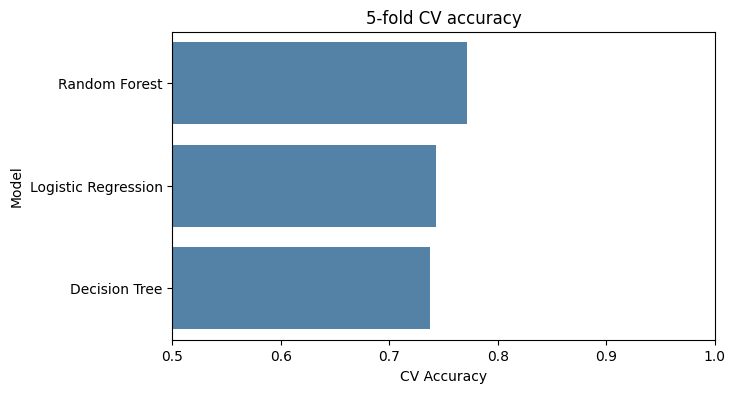

In [20]:
candidates = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
}
rows = []
for name, m in candidates.items():
    s = cross_val_score(m, X_train, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
    rows.append((name, s.mean(), s.std()))
cmp_df = pd.DataFrame(rows, columns=["Model", "CV Accuracy", "Std"]).sort_values("CV Accuracy", ascending=False)
display(cmp_df.round(4))

plt.figure(figsize=(7, 4))
sns.barplot(data=cmp_df, x="CV Accuracy", y="Model", color="steelblue")
plt.xlim(0.5, 1); plt.title("5-fold CV accuracy"); plt.show()

## Step 11 — Hyperparameter Tuning (RandomizedSearchCV)

In [21]:
param_dist = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [None, 10, 15, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2", 0.5],
}
search = RandomizedSearchCV(RandomForestClassifier(random_state=SEED, n_jobs=-1), param_dist, n_iter=25,
                            scoring="f1", cv=cv, random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)

print("Best CV F1:", round(search.best_score_, 4))
print("Best params:", search.best_params_)
best_rf = search.best_estimator_

Best CV F1: 0.822
Best params: {'n_estimators': 300, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_depth': 30}


## Step 12 — Final Evaluation of the Tuned Model (test set)

Accuracy : 0.7716
Precision: 0.8000
Recall   : 0.8468
F1-score : 0.8228
ROC-AUC  : 0.8375

               precision    recall  f1-score   support

        Poor      0.716     0.646     0.679       398
        Good      0.800     0.847     0.823       666

    accuracy                          0.772      1064
   macro avg      0.758     0.746     0.751      1064
weighted avg      0.769     0.772     0.769      1064



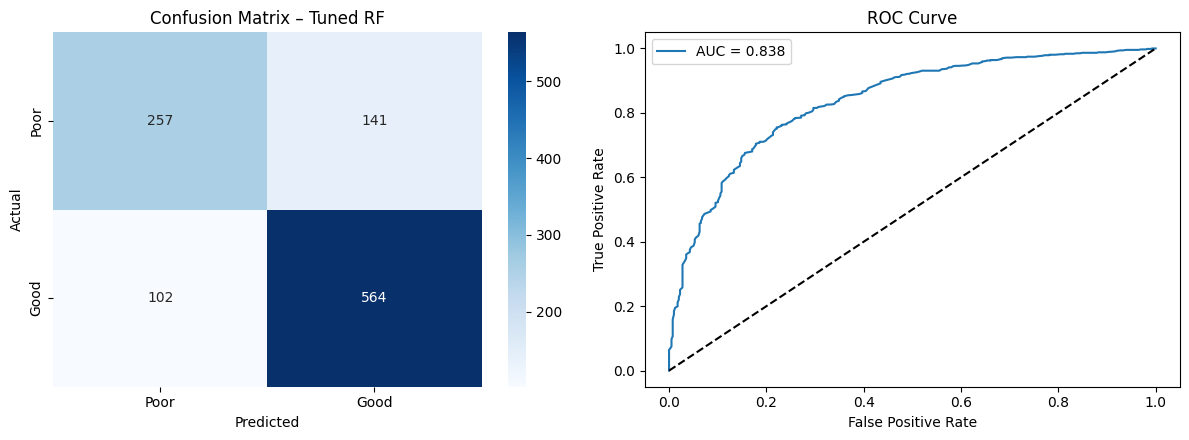

In [22]:
y_pred = best_rf.predict(X_test)
y_prob = best_rf.predict_proba(X_test)[:, 1]

print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.4f}")
print("\n", classification_report(y_test, y_pred, target_names=["Poor", "Good"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Poor", "Good"], yticklabels=["Poor", "Good"], ax=ax[0])
ax[0].set_title("Confusion Matrix – Tuned RF"); ax[0].set_xlabel("Predicted"); ax[0].set_ylabel("Actual")

fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, y_prob):.3f}")
ax[1].plot([0, 1], [0, 1], "k--"); ax[1].set_title("ROC Curve"); ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 13 — Feature Importance (the main goal of the project)

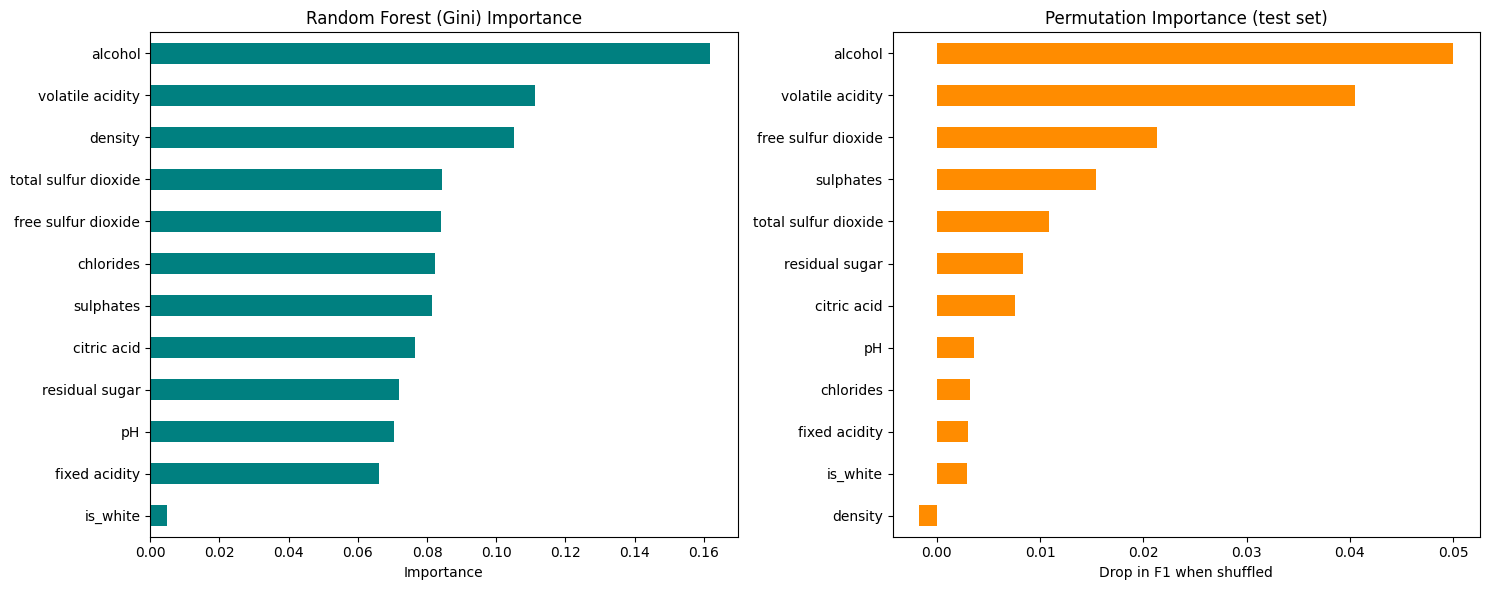

,Gini importance,Permutation importance,Gini rank,Permutation rank
alcohol,0.1616,0.0500,1,1
volatile acidity,0.1113,0.0405,2,2
density,0.1052,-0.0017,3,12
total sulfur dioxide,0.0842,0.0109,4,5
free sulfur dioxide,0.0841,0.0213,5,3
chlorides,0.0823,0.0032,6,9
sulphates,0.0814,0.0154,7,4
citric acid,0.0765,0.0076,8,7
residual sugar,0.0719,0.0083,9,6
pH,0.0704,0.0036,10,8


In [23]:
# (a) Impurity-based (Gini) importance
gini = pd.Series(best_rf.feature_importances_, index=FEATURES).sort_values()

# (b) Permutation importance on unseen test data (less biased toward high-cardinality features)
perm = permutation_importance(best_rf, X_test, y_test, scoring="f1", n_repeats=20, random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=FEATURES).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
gini.plot(kind="barh", color="teal", ax=ax[0]); ax[0].set_title("Random Forest (Gini) Importance"); ax[0].set_xlabel("Importance")
perm_s.plot(kind="barh", color="darkorange", ax=ax[1]); ax[1].set_title("Permutation Importance (test set)"); ax[1].set_xlabel("Drop in F1 when shuffled")
plt.tight_layout(); plt.show()

rank = pd.DataFrame({"Gini importance": gini, "Permutation importance": perm_s}).sort_values("Gini importance", ascending=False)
rank["Gini rank"] = rank["Gini importance"].rank(ascending=False).astype(int)
rank["Permutation rank"] = rank["Permutation importance"].rank(ascending=False).astype(int)
display(rank.round(4))

## Step 14 — Regression View: Predict the Exact Quality Score

RMSE: 0.708
MAE : 0.543
R²  : 0.377


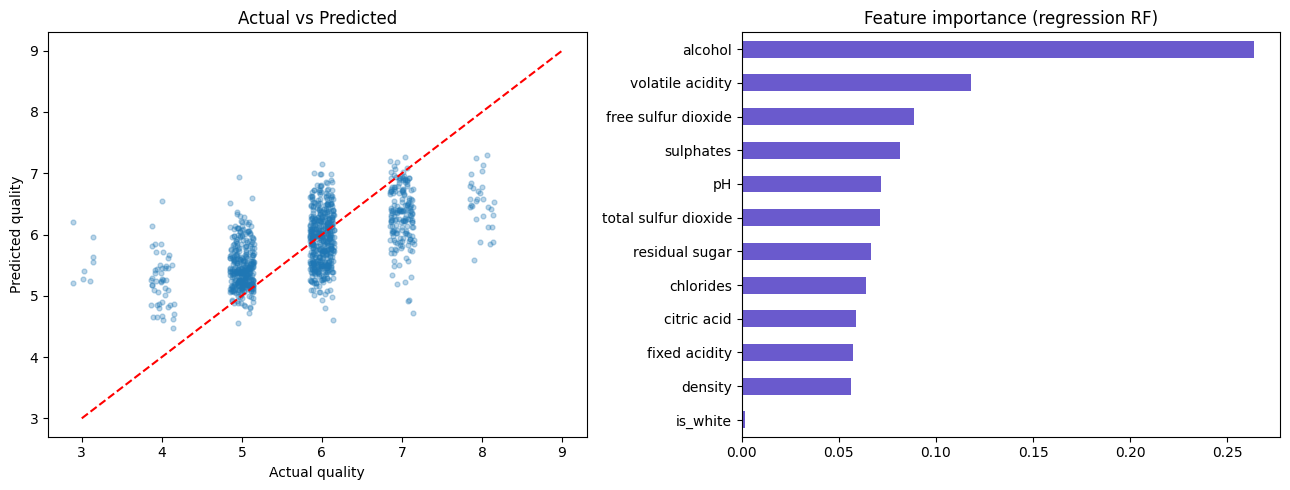

In [24]:
y_reg = data["quality"]
reg = RandomForestRegressor(n_estimators=500, random_state=SEED, n_jobs=-1)
reg.fit(X_train, y_reg.loc[X_train.index])
p = reg.predict(X_test)
yt = y_reg.loc[X_test.index]

print(f"RMSE: {np.sqrt(mean_squared_error(yt, p)):.3f}")
print(f"MAE : {mean_absolute_error(yt, p):.3f}")
print(f"R²  : {r2_score(yt, p):.3f}")

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(yt + np.random.uniform(-.15, .15, len(yt)), p, alpha=.3, s=12)
ax[0].plot([3, 9], [3, 9], "r--"); ax[0].set_xlabel("Actual quality"); ax[0].set_ylabel("Predicted quality"); ax[0].set_title("Actual vs Predicted")
pd.Series(reg.feature_importances_, index=FEATURES).sort_values().plot(kind="barh", color="slateblue", ax=ax[1])
ax[1].set_title("Feature importance (regression RF)")
plt.tight_layout(); plt.show()

## Step 15 — Save the Trained Model & Predict a New Wine

In [25]:
joblib.dump({"model": best_rf, "features": FEATURES, "threshold": GOOD_THRESHOLD}, "wine_rf_model.joblib")
print("Saved -> wine_rf_model.joblib")

new_wine = pd.DataFrame([{'fixed acidity': 7.4, 'volatile acidity': 0.70, 'citric acid': 0.0, 'residual sugar': 1.9, 'chlorides': 0.076,
                          'free sulfur dioxide': 11, 'total sulfur dioxide': 34, 'density': 0.9978, 'pH': 3.51, 'sulphates': 0.56,
                          'alcohol': 9.4, 'is_white': 0}])[FEATURES]
prob = best_rf.predict_proba(new_wine)[0, 1]
print(f"Predicted: {'GOOD' if prob >= 0.5 else 'POOR'}  (P(good) = {prob:.2f})")

Saved -> wine_rf_model.joblib
Predicted: POOR  (P(good) = 0.04)


## Step 16 — Summary & Conclusion

In [26]:
top3 = gini.sort_values(ascending=False).head(3).index.tolist()
print(f"Dataset: {df.shape[0]} rows -> {df_clean.shape[0]} after removing {df.shape[0]-df_clean.shape[0]} duplicates")
print(f"Task: good (quality >= {GOOD_THRESHOLD}) vs poor | Best model: tuned Random Forest")
print(f"Test accuracy = {accuracy_score(y_test, y_pred):.3f}, F1 = {f1_score(y_test, y_pred):.3f}, ROC-AUC = {roc_auc_score(y_test, y_prob):.3f}")
print(f"Top-3 most important features: {top3}")
print(f"Regression view: R² = {r2_score(yt, p):.3f}, RMSE = {np.sqrt(mean_squared_error(yt, p)):.3f}")

Dataset: 6497 rows -> 5320 after removing 1177 duplicates
Task: good (quality >= 6) vs poor | Best model: tuned Random Forest
Test accuracy = 0.772, F1 = 0.823, ROC-AUC = 0.838
Top-3 most important features: ['alcohol', 'volatile acidity', 'density']
Regression view: R² = 0.377, RMSE = 0.708


### Conclusion
* A tuned **Random Forest classifier** separates good (quality ≥ 6) from poor wines with roughly **77 % accuracy, 0.82 F1 and 0.84 ROC-AUC** on unseen data, beating Logistic Regression and a Decision Tree in cross-validation.
* Both Gini and permutation importance agree that **alcohol, volatile acidity and density** are the most influential properties; higher alcohol and lower volatile acidity point to better wines.
* The regression forest explains only ~38 % of variance in the exact score (R²), so quality is only partly determined by lab measurements — taster subjectivity and unmeasured factors (grape, brand, aroma) matter.
* **Limitations / next steps:** class overlap around scores 5–6, no scores at the extremes; try a premium threshold (`GOOD_THRESHOLD = 7`), class weighting, or gradient boosting.